# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

Tugas ini menguji pemahaman Anda tentang materi **Simple Regression** (`simple_regression/regression_1.ipynb`) dan **Simple Classification** (`simple_classification/classification_1.ipynb`). Anda akan menerapkan algoritma yang sama pada **dataset baru**, lalu mengembangkannya dengan evaluasi dan eksperimen tambahan.

**Identitas Mahasiswa**
- Nama  : Muhammad Rizky Angkasa Putra Anwar
- NIM   : 241011400213
- Kelas : Reg B 

## 📌 Ketentuan Pengerjaan

1. Kerjakan semua soal di notebook ini pada sel kode / sel markdown yang telah disediakan.
2. **Model dan metrik evaluasi wajib diimplementasikan sendiri** dengan NumPy, seperti pada materi (`train_test_split`, `LinearRegression`, `LinearRegressionGD`, `LogisticRegression`, `accuracy_score`, `confusion_matrix`). Anda boleh menyalin implementasi dari materi.
   - Library yang boleh dipakai: `numpy`, `pandas`, `matplotlib`.
   - `scikit-learn` **tidak boleh** dipakai untuk model dan metrik, kecuali pada soal bonus untuk membandingkan hasil.
3. **`random_state` = 2 digit terakhir NIM Anda** (contoh: NIM `...0347` → `random_state=47`; jika `00`, gunakan `100`). Karena itu, setiap mahasiswa akan mendapat hasil angka yang berbeda.
4. Setiap soal yang meminta **penjelasan/analisis** dijawab dengan kalimat Anda sendiri pada sel markdown, dan harus merujuk ke angka/grafik hasil Anda.
5. Notebook harus **sudah dijalankan** (*Run All*) sehingga semua output dan grafik terlihat saat dibuka di GitHub.

## 📂 Dataset
Dataset disediakan di folder ini:

| File | Kolom | Keterangan |
|---|---|---|
| `Ads_Data.csv` | `BiayaIklan`, `Penjualan` | Biaya iklan per bulan (juta Rp) dan penjualan per bulan (juta Rp), 40 data |
| `Email_Data.csv` | `JumlahLink`, `KataPromo`, `Spam` | Jumlah link dan jumlah kata promosi dalam sebuah email, serta label Spam (1) / Bukan Spam (0), 60 data |

## 📤 Cara Pengumpulan

1. Buat **repositori baru** di akun GitHub Anda masing-masing dengan nama: `uts-machine-learning-<NIM>` (contoh: `uts-machine-learning-20230801047`).
2. Atur repositori menjadi **Public**.
3. Struktur repositori minimal:
   ```
   uts-machine-learning-<NIM>/
   ├── README.md            # Nama, NIM, Kelas, dan ringkasan hasil (R², akurasi, dll)
   ├── tugas_UTS.ipynb      # notebook ini, sudah dijalankan lengkap dengan output
   ├── Ads_Data.csv
   └── Email_Data.csv
   ```
4. Kumpulkan **link repositori GitHub** di halaman **UTS pada Mentari**.
5. Batas waktu pengumpulan (hari terakhir periode UTS):

| Kelas | Batas Pengumpulan |
|---|---|
| **Reg B** | **Jumat, 23 Oktober 2026, pukul 23:59 WIB** |
| **Reg C** | **Sabtu, 24 Oktober 2026, pukul 23:59 WIB** |

> ⚠️ Yang dinilai adalah **commit terakhir sebelum batas waktu**. Commit setelah batas waktu tidak akan dinilai. Pastikan link yang dikumpulkan bisa dibuka (repositori tidak *private*).

## 🧮 Penilaian

| Bagian | Bobot |
|---|---|
| Bagian A – Linear Regression | 35% |
| Bagian B – Logistic Regression | 40% |
| Bagian C – Pemahaman Konsep | 15% |
| Kerapihan repositori, README, dan notebook (output lengkap, kode rapi & diberi komentar) | 10% |
| Bonus – Perbandingan dengan scikit-learn | +5 |

In [21]:
# Import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


RANDOM_STATE = 13  # 2 digit terakhir NIM

In [22]:
def train_test_split(X, y, test_size=0.2, random_state=None):
    rng = np.random.RandomState(random_state)
    idx = rng.permutation(len(X))
    n_test = int(len(X) * test_size)
    test_idx, train_idx = idx[:n_test], idx[n_test:]
    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]

---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.

### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).

   BiayaIklan  Penjualan
0         0.8       34.3
1         0.9       38.8
2         1.0       33.2
3         1.3       36.0
4         1.7       51.3
Jumlah baris: 40
Shape X: (40, 1)
Shape y: (40,)


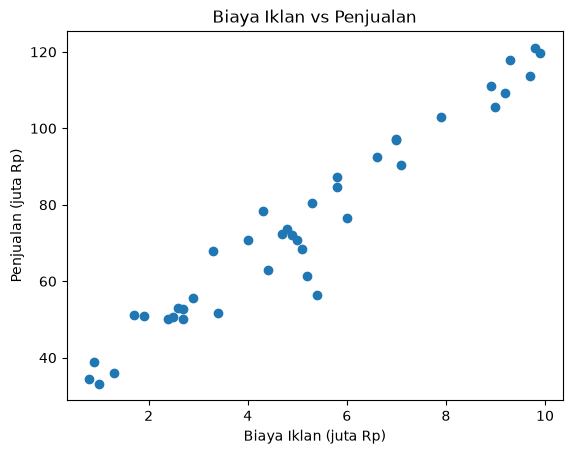

In [23]:
# Jawaban A1
df = pd.read_csv("Ads_Data.csv")
print(df.head())
print("Jumlah baris:", len(df))

X = df[["BiayaIklan"]].values   
y = df["Penjualan"].values
print("Shape X:", X.shape)
print("Shape y:", y.shape)

plt.scatter(X, y)
plt.title("Biaya Iklan vs Penjualan")
plt.xlabel("Biaya Iklan (juta Rp)")
plt.ylabel("Penjualan (juta Rp)")
plt.show()

### Soal A2 – Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.

In [24]:
# Jawaban A2
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

print("Shape X_train:", X_train.shape)
print("Shape X_test :", X_test.shape)
print("Shape y_train:", y_train.shape)
print("Shape y_test :", y_test.shape)

Shape X_train: (32, 1)
Shape X_test : (8, 1)
Shape y_train: (32,)
Shape y_test : (8,)


### Soal A3 – Training dengan Normal Equation
1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini (misal: "setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sebesar ..."). tolong kasih tau gua cara lengkap ngerjain nya

In [25]:
class LinearRegression:
    def fit(self, X, y):
        Xb = np.c_[np.ones(len(X)), X]                  # tambah kolom 1 buat intercept
        theta = np.linalg.pinv(Xb.T @ Xb) @ Xb.T @ y    # normal equation
        self.intercept_ = theta[0]
        self.coef_ = theta[1:]
        return self

    def predict(self, X):
        return self.intercept_ + X @ self.coef_

In [26]:
# Jawaban A3
model = LinearRegression()
model.fit(X_train, y_train)

b = model.intercept_
m = model.coef_[0]
print("Intercept (b):", b)
print("Koefisien (m):", m)
print(f"Persamaan: y_hat = {b:.4f} + {m:.4f} * X")

Intercept (b): 27.645637920561903
Koefisien (m): 9.016263910280122
Persamaan: y_hat = 27.6456 + 9.0163 * X


**Jawaban A3 (interpretasi):**

Jawaban A3 (interpretasi):

Dari data training didapat persamaan ŷ = 27,65 + 9,02X. Nilai m = 9,02 artinya setiap biaya iklan naik 1 juta Rp, penjualan diperkirakan naik sekitar 9,02 juta Rp. Intercept 27,65 itu perkiraan penjualan kalau biaya iklan 0, jadi toko tetap punya penjualan dasar sekitar 27,65 juta Rp tanpa iklan.

### Soal A4 – Evaluasi Model
Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?

In [27]:
# Jawaban A4
def mae(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))

def mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

def rmse(y_true, y_pred):
    return np.sqrt(mse(y_true, y_pred))

def r2_score(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1 - ss_res / ss_tot

y_pred_train = model.predict(X_train)
y_pred_test = model.predict(X_test)

hasil = pd.DataFrame({
    "Metrik": ["MAE", "MSE", "RMSE", "R2"],
    "Training": [mae(y_train, y_pred_train), mse(y_train, y_pred_train),
                 rmse(y_train, y_pred_train), r2_score(y_train, y_pred_train)],
    "Testing": [mae(y_test, y_pred_test), mse(y_test, y_pred_test),
                rmse(y_test, y_pred_test), r2_score(y_test, y_pred_test)]
})
print(hasil)

  Metrik   Training    Testing
0    MAE   4.469115   5.599090
1    MSE  36.323554  40.697137
2   RMSE   6.026902   6.379431
3     R2   0.941590   0.865991


**Jawaban A4 (analisis):**

Jawaban A4 (analisis):

RMSE testing saya 6,38, artinya rata-rata tebakan penjualan model meleset sekitar 6,38 juta Rp dari nilai aslinya. Kalau dibandingin rata-rata penjualan yang sekitar 74 juta Rp, kesalahan segitu masih kecil. R² testing 0,866 artinya sekitar 86,6% variasi penjualan bisa dijelasin sama biaya iklan, sisanya faktor lain yang nggak ada di data. Menurut saya modelnya sudah cukup baik, soalnya R² training (0,942) dan testing (0,866) sama-sama tinggi dan selisihnya nggak terlalu jauh, jadi nggak ada tanda overfitting yang parah. Performa di testing sedikit lebih jelek karena datanya cuma 8 baris, jadi hasilnya gampang goyang.

### Soal A5 – Gradient Descent & Learning Rate
1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (boleh dalam satu grafik atau *subplot*; gunakan skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> *Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya.*

In [28]:
class LinearRegressionGD:
    def __init__(self, learning_rate=0.01, n_iterations=1000):
        self.lr = learning_rate
        self.n_iterations = n_iterations

    def fit(self, X, y):
        n = len(X)
        self.intercept_ = 0.0
        self.coef_ = np.zeros(X.shape[1])
        self.losses_ = []
        for _ in range(self.n_iterations):
            y_pred = self.intercept_ + X @ self.coef_
            error = y_pred - y
            self.losses_.append(np.mean(error ** 2))               # loss MSE
            self.intercept_ -= self.lr * (2 / n) * np.sum(error)   # update b
            self.coef_ -= self.lr * (2 / n) * (X.T @ error)        # update m
        return self

    def predict(self, X):
        return self.intercept_ + X @ self.coef_

Normal equation: b = 27.6456, m = 9.0163

lr = 0.001: b = 25.346581384387136, m = 9.388713391859287, loss akhir = 37.63002649169184
lr = 0.02: b = 27.645637920562088, m = 9.01626391028008, loss akhir = 36.323553692698056
lr = 0.1: b = nan, m = nan, loss akhir = nan


C:\Users\rangk\AppData\Local\Temp\ipykernel_2840\3726502896.py:14: RuntimeWarning: overflow encountered in square
  self.losses_.append(np.mean(error ** 2))               # loss MSE
c:\ProgramData\anaconda3\Lib\site-packages\numpy\_core\_methods.py:132: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)
C:\Users\rangk\AppData\Local\Temp\ipykernel_2840\3726502896.py:16: RuntimeWarning: overflow encountered in matmul
  self.coef_ -= self.lr * (2 / n) * (X.T @ error)        # update m
C:\Users\rangk\AppData\Local\Temp\ipykernel_2840\3726502896.py:16: RuntimeWarning: invalid value encountered in subtract
  self.coef_ -= self.lr * (2 / n) * (X.T @ error)        # update m
c:\ProgramData\anaconda3\Lib\site-packages\matplotlib\scale.py:375: RuntimeWarning: overflow encountered in exp
  return np.exp(values * np.log(self.base))


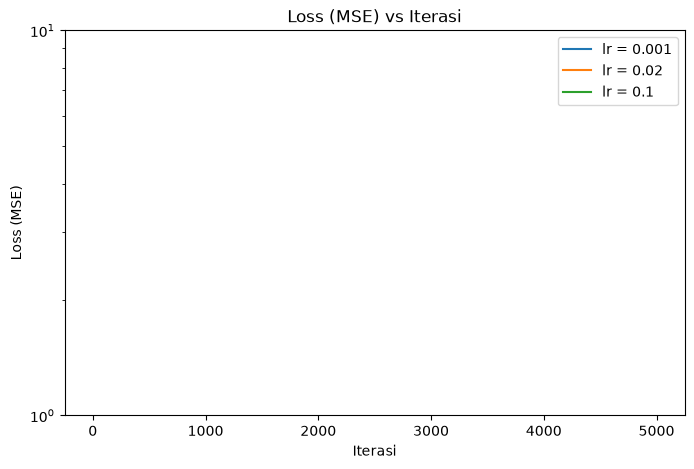

In [29]:
# Jawaban A5
learning_rates = [0.001, 0.02, 0.1]
models_gd = {}

print(f"Normal equation: b = {model.intercept_:.4f}, m = {model.coef_[0]:.4f}\n")
for lr in learning_rates:
    gd = LinearRegressionGD(learning_rate=lr, n_iterations=5000)
    gd.fit(X_train, y_train)
    models_gd[lr] = gd
    print(f"lr = {lr}: b = {gd.intercept_}, m = {gd.coef_[0]}, loss akhir = {gd.losses_[-1]}")

# Grafik loss vs iterasi (skala log)
plt.figure(figsize=(8, 5))
for lr in learning_rates:
    losses = np.array(models_gd[lr].losses_, dtype=float)
    losses[~np.isfinite(losses)] = np.nan   # loss yang meledak (inf) tidak digambar
    plt.plot(losses, label=f"lr = {lr}")
plt.yscale("log")
plt.title("Loss (MSE) vs Iterasi")
plt.xlabel("Iterasi")
plt.ylabel("Loss (MSE)")
plt.legend()
plt.show()

**Jawaban A5 (analisis):**

Jawaban A5 (analisis):

Hasil gradient descent beda-beda tergantung learning rate-nya. Dengan lr = 0,001, setelah 5000 iterasi intercept masih 25,35 dan koefisien 9,39, jadi belum sampai ke hasil normal equation (27,65 dan 9,02) dan loss akhirnya masih 37,6. Ini terlalu lambat, karena langkah update tiap iterasinya terlalu kecil. Dengan lr = 0,02, hasilnya hampir sama persis dengan normal equation (b = 27,65, m = 9,02, loss 36,32) dan lossnya turun cepat lalu stabil, jadi ini yang paling pas. Dengan lr = 0,1, model gagal konvergen (divergen). Langkah update terlalu besar sehingga parameter melompat melewati titik minimum dan makin jauh tiap iterasi, sampai lossnya meledak. RuntimeWarning overflow muncul karena angkanya jadi terlalu besar untuk disimpan komputer (melewati batas bilangan float), dan itu justru tanda kalau learning rate-nya kegedean.

### Soal A6 – Visualisasi & Prediksi
1. Buat grafik *scatter* data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.

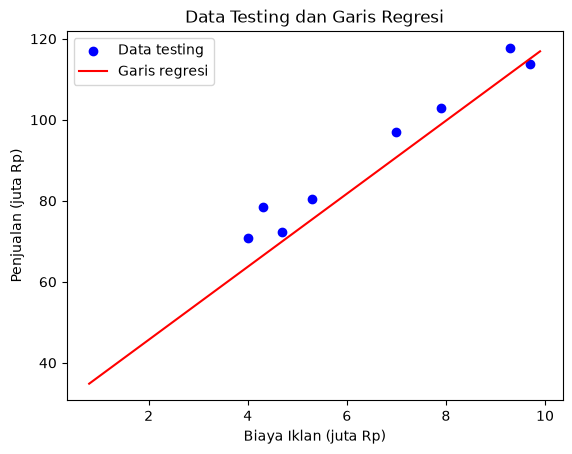

Biaya iklan 4.5 juta -> prediksi penjualan 68.22 juta
Biaya iklan 7.0 juta -> prediksi penjualan 90.76 juta
Biaya iklan 12.0 juta -> prediksi penjualan 135.84 juta


In [30]:
# Jawaban A6
# 1. Scatter data testing + garis regresi
x_line = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
y_line = model.predict(x_line)

plt.scatter(X_test, y_test, color="blue", label="Data testing")
plt.plot(x_line, y_line, color="red", label="Garis regresi")
plt.title("Data Testing dan Garis Regresi")
plt.xlabel("Biaya Iklan (juta Rp)")
plt.ylabel("Penjualan (juta Rp)")
plt.legend()
plt.show()

# 2. Prediksi untuk biaya iklan baru
X_baru = np.array([[4.5], [7], [12]])
y_baru = model.predict(X_baru)
for x_val, y_val in zip(X_baru.flatten(), y_baru):
    print(f"Biaya iklan {x_val} juta -> prediksi penjualan {y_val:.2f} juta")

**Jawaban A6 (analisis):**

Jawaban A6 (analisis):

Dari grafik, titik data testing letaknya dekat dengan garis regresi, jadi garisnya cukup mewakili pola datanya. Prediksi penjualan untuk biaya iklan 4,5 juta, 7 juta, dan 12 juta berturut-turut adalah sekitar 68,22 juta, 90,76 juta, dan 135,84 juta Rp. Prediksi 4,5 dan 7 juta cukup bisa dipercaya karena angkanya ada di dalam rentang data (0,8 sampai 9,9 juta), jadi model sudah pernah "melihat" kondisi seperti itu. Prediksi untuk 12 juta kurang bisa dipercaya karena ini ekstrapolasi: 12 juta di luar rentang data, dan model cuma ngikutin garis lurus tanpa tahu apakah pola itu masih berlaku di sana. Di dunia nyata, kenaikan biaya iklan biasanya ada batasnya (misalnya pasar sudah jenuh), jadi penjualannya belum tentu terus naik sebesar 9,02 juta tiap tambahan 1 juta iklan. Hasil 135,84 juta itu cukup dijadikan perkiraan kasar, bukan angka yang pasti.

---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Gunakan dataset `Email_Data.csv`.

### Soal B1 – Load & Visualisasi Data
1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat *scatter plot* `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).

   JumlahLink  KataPromo  Spam
0           0          0     0
1           2          4     0
2           6          7     1
3          10          8     1
4           8          7     1
Jumlah baris: 60

Jumlah per kelas:
Spam
0    35
1    25
Name: count, dtype: int64

Shape X: (60, 2)
Shape y: (60,)


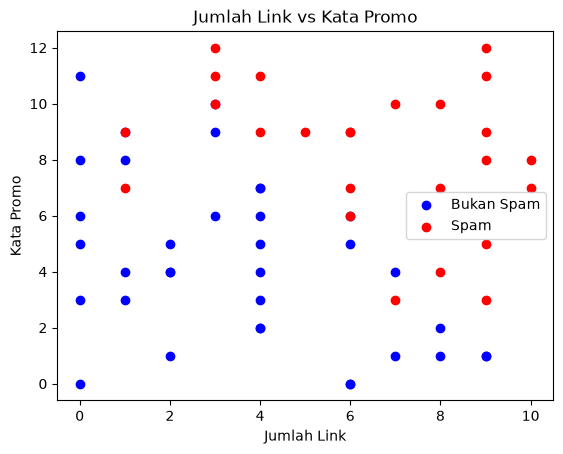

In [31]:
# Jawaban B1
df_email = pd.read_csv("Email_Data.csv")
print(df_email.head())
print("Jumlah baris:", len(df_email))
print("\nJumlah per kelas:")
print(df_email["Spam"].value_counts())

X_email = df_email[["JumlahLink", "KataPromo"]].values
y_email = df_email["Spam"].values
print("\nShape X:", X_email.shape)
print("Shape y:", y_email.shape)

plt.scatter(X_email[y_email == 0, 0], X_email[y_email == 0, 1], color="blue", label="Bukan Spam")
plt.scatter(X_email[y_email == 1, 0], X_email[y_email == 1, 1], color="red", label="Spam")
plt.title("Jumlah Link vs Kata Promo")
plt.xlabel("Jumlah Link")
plt.ylabel("Kata Promo")
plt.legend()
plt.show()

### Soal B2 – Split Data & Training
1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:
   $$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$
4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?

In [32]:
class LogisticRegression:
    def __init__(self, learning_rate=0.1, n_iterations=1000):
        self.lr = learning_rate
        self.n_iterations = n_iterations

    def _sigmoid(self, z):
        return 1 / (1 + np.exp(-z))

    def fit(self, X, y):
        n = len(X)
        self.intercept_ = 0.0
        self.coef_ = np.zeros(X.shape[1])
        self.losses_ = []
        for _ in range(self.n_iterations):
            p = self._sigmoid(self.intercept_ + X @ self.coef_)
            p_clip = np.clip(p, 1e-15, 1 - 1e-15)          # biar log nggak error
            loss = -np.mean(y * np.log(p_clip) + (1 - y) * np.log(1 - p_clip))
            self.losses_.append(loss)
            self.intercept_ -= self.lr * np.mean(p - y)
            self.coef_ -= self.lr * (X.T @ (p - y)) / n
        return self

    def predict_proba(self, X):
        return self._sigmoid(self.intercept_ + X @ self.coef_)

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

Shape: (45, 2) (15, 2) (45,) (15,)
Intercept (b): -10.433431988665488
Koefisien m1 (JumlahLink): 0.9076062481905138
Koefisien m2 (KataPromo): 0.9925338277725972
P(Spam) = sigmoid(-10.4334 + 0.9076 * JumlahLink + 0.9925 * KataPromo)


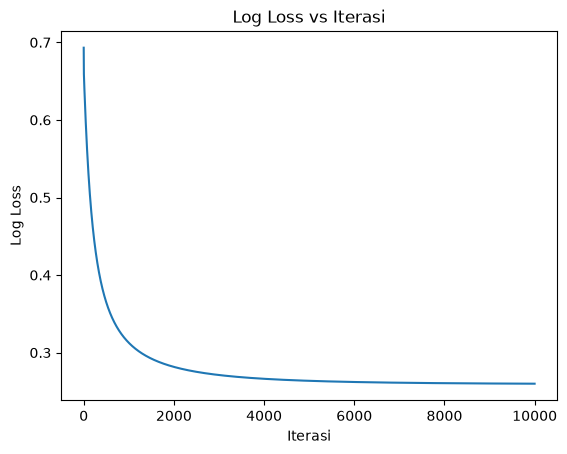

Loss awal: 0.6931471805599452 | Loss akhir: 0.25995310634259605


In [33]:
# Jawaban B2
X_train_e, X_test_e, y_train_e, y_test_e = train_test_split(X_email, y_email, test_size=0.25, random_state=RANDOM_STATE)
print("Shape:", X_train_e.shape, X_test_e.shape, y_train_e.shape, y_test_e.shape)

log_model = LogisticRegression(learning_rate=0.1, n_iterations=10000)
log_model.fit(X_train_e, y_train_e)

b = log_model.intercept_
m1, m2 = log_model.coef_
print("Intercept (b):", b)
print("Koefisien m1 (JumlahLink):", m1)
print("Koefisien m2 (KataPromo):", m2)
print(f"P(Spam) = sigmoid({b:.4f} + {m1:.4f} * JumlahLink + {m2:.4f} * KataPromo)")

plt.plot(log_model.losses_)
plt.title("Log Loss vs Iterasi")
plt.xlabel("Iterasi")
plt.ylabel("Log Loss")
plt.show()
print("Loss awal:", log_model.losses_[0], "| Loss akhir:", log_model.losses_[-1])

**Jawaban B2 (analisis):**

Jawaban B2 (analisis):

Persamaan yang didapat: P(Spam) = σ(-10,43 + 0,908·JumlahLink + 0,993·KataPromo). Koefisien m1 dan m2 sama-sama positif, artinya makin banyak link dan makin banyak kata promosi di email, probabilitas email itu spam makin tinggi. Dari grafik log loss, lossnya turun tajam di awal, dari sekitar 0,693 sampai sekitar 0,31 di iterasi ke-1000, lalu makin landai dan berakhir di sekitar 0,260 pada iterasi ke-10000. Jadi loss sudah turun dan stabil, tandanya training sudah konvergen dan 10000 iterasi sudah cukup.

### Soal B3 – Evaluasi Model
Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$
Precision = \frac{TP}{TP + FP} \qquad
Recall = \frac{TP}{TP + FN} \qquad
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (*false positive*) dan **FN** (*false negative*) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?

In [34]:
# Jawaban B3
def accuracy_score(y_true, y_pred):
    return np.mean(y_true == y_pred)

def confusion_matrix(y_true, y_pred):
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    tp = np.sum((y_true == 1) & (y_pred == 1))
    return np.array([[tn, fp], [fn, tp]])

def precision_score(y_true, y_pred):
    tp = np.sum((y_true == 1) & (y_pred == 1))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    return tp / (tp + fp) if (tp + fp) > 0 else 0.0

def recall_score(y_true, y_pred):
    tp = np.sum((y_true == 1) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    return tp / (tp + fn) if (tp + fn) > 0 else 0.0

def f1_score(y_true, y_pred):
    p = precision_score(y_true, y_pred)
    r = recall_score(y_true, y_pred)
    return 2 * p * r / (p + r) if (p + r) > 0 else 0.0

y_pred_e = log_model.predict(X_test_e)

print("Accuracy :", accuracy_score(y_test_e, y_pred_e))
print("Confusion matrix (baris: aktual 0,1 | kolom: prediksi 0,1):")
print(confusion_matrix(y_test_e, y_pred_e))
print("Precision:", precision_score(y_test_e, y_pred_e))
print("Recall   :", recall_score(y_test_e, y_pred_e))
print("F1-score :", f1_score(y_test_e, y_pred_e))

Accuracy : 0.8
Confusion matrix (baris: aktual 0,1 | kolom: prediksi 0,1):
[[8 3]
 [0 4]]
Precision: 0.5714285714285714
Recall   : 1.0
F1-score : 0.7272727272727273


**Jawaban B3 (analisis):**

Pada data testing (15 email), model punya accuracy 0,80, precision 0,571, recall 1,0, dan F1 0,727. Confusion matrix-nya menunjukkan TP = 4, TN = 8, FP = 3, dan FN = 0. FP artinya email yang sebenarnya bukan spam tapi diprediksi spam, jadi email biasa nyasar ke folder spam. FN artinya email spam yang lolos dan dianggap bukan spam, jadi spam masuk ke inbox. Di hasil saya, model nggak pernah meloloskan spam (FN = 0, makanya recall 1,0), tapi ada 3 email biasa yang salah dibuang sebagai spam, makanya precision cuma 0,571. Menurut saya FP lebih merugikan, karena email penting seperti info kuliah, tagihan, atau lamaran kerja bisa terlewat kalau masuk ke spam, sedangkan kalau FN pengguna cuma perlu menghapus spam yang kebetulan masuk ke inbox.

### Soal B4 – Decision Boundary
1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):
   $$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$
2. Buat visualisasi data **testing** beserta *background* probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.

Decision boundary: x2 = -(-10.4334 + 0.9076 * x1) / 0.9925
                   x2 = 10.5119 - 0.9144 * x1


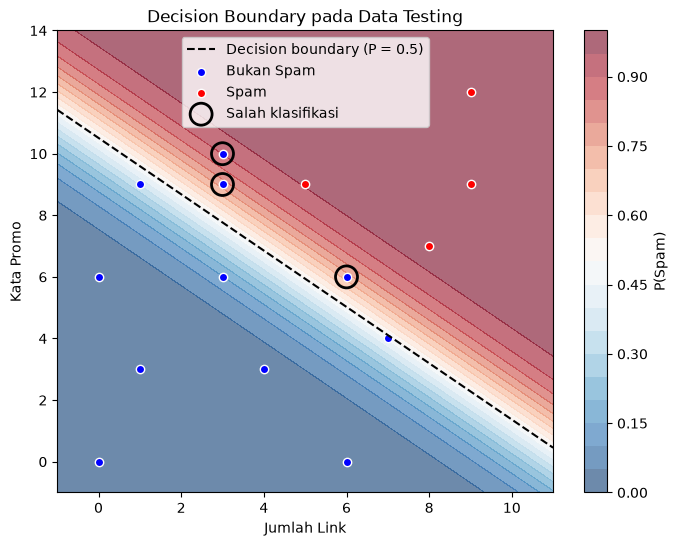

Data testing yang salah diklasifikasikan:
JumlahLink=6, KataPromo=6 | aktual=0, prediksi=1, P(Spam)=0.725
JumlahLink=3, KataPromo=9 | aktual=0, prediksi=1, P(Spam)=0.772
JumlahLink=3, KataPromo=10 | aktual=0, prediksi=1, P(Spam)=0.902


In [35]:
# Jawaban B4
b = log_model.intercept_
m1, m2 = log_model.coef_

# 1. Persamaan decision boundary: x2 = -(b + m1*x1) / m2
print(f"Decision boundary: x2 = -({b:.4f} + {m1:.4f} * x1) / {m2:.4f}")
print(f"                   x2 = {-b/m2:.4f} - {m1/m2:.4f} * x1")

# 2. Background probabilitas (contourf) + garis boundary
x1_range = np.linspace(-1, 11, 200)
x2_range = np.linspace(-1, 14, 200)
xx1, xx2 = np.meshgrid(x1_range, x2_range)
grid = np.c_[xx1.ravel(), xx2.ravel()]
prob_grid = log_model.predict_proba(grid).reshape(xx1.shape)

plt.figure(figsize=(8, 6))
cs = plt.contourf(xx1, xx2, prob_grid, levels=20, cmap="RdBu_r", alpha=0.6)
plt.colorbar(cs, label="P(Spam)")

x1_line = np.linspace(-1, 11, 100)
x2_line = -(b + m1 * x1_line) / m2
plt.plot(x1_line, x2_line, "k--", label="Decision boundary (P = 0.5)")

plt.scatter(X_test_e[y_test_e == 0, 0], X_test_e[y_test_e == 0, 1], color="blue", edgecolor="white", label="Bukan Spam")
plt.scatter(X_test_e[y_test_e == 1, 0], X_test_e[y_test_e == 1, 1], color="red", edgecolor="white", label="Spam")

# 3. Tandai data yang salah diklasifikasikan
salah = y_pred_e != y_test_e
plt.scatter(X_test_e[salah, 0], X_test_e[salah, 1], s=250, facecolors="none", edgecolors="black", linewidths=2, label="Salah klasifikasi")

plt.xlim(-1, 11)
plt.ylim(-1, 14)
plt.title("Decision Boundary pada Data Testing")
plt.xlabel("Jumlah Link")
plt.ylabel("Kata Promo")
plt.legend()
plt.show()

print("Data testing yang salah diklasifikasikan:")
for x, yt, yp, pr in zip(X_test_e[salah], y_test_e[salah], y_pred_e[salah], log_model.predict_proba(X_test_e[salah])):
    print(f"JumlahLink={x[0]}, KataPromo={x[1]} | aktual={yt}, prediksi={yp}, P(Spam)={pr:.3f}")

**Jawaban B4 (analisis):**


Dari koefisien hasil training, decision boundary-nya x2 = -(-10,43 + 0,908·x1) / 0,993, atau sekitar x2 = 10,51 - 0,914·x1. Garis ini memisahkan area spam (di kanan atas, background merah) dan bukan spam (di kiri bawah, background biru). Di data testing ada 3 titik yang salah diklasifikasikan, yaitu (JumlahLink, KataPromo) = (6, 6), (3, 9), dan (3, 10). Ketiganya aslinya bukan spam tapi jatuh di sisi spam garis boundary (probabilitasnya 0,725, 0,772, dan 0,902), jadi semuanya false positive. Ini masuk akal, karena email biasa itu kebetulan punya jumlah link atau kata promo yang lumayan banyak, sehingga mirip email spam. Tidak ada spam yang lolos, sesuai FN = 0 di Soal B3.

### Soal B5 – Eksperimen Threshold
Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.

In [36]:
# Jawaban B5
from IPython.display import display

proba_test = log_model.predict_proba(X_test_e)

baris = []
for t in [0.3, 0.5, 0.7]:
    y_pred_t = (proba_test >= t).astype(int)
    cm = confusion_matrix(y_test_e, y_pred_t)
    baris.append({
        "Threshold": t,
        "TN": cm[0, 0], "FP": cm[0, 1], "FN": cm[1, 0], "TP": cm[1, 1],
        "Precision": round(precision_score(y_test_e, y_pred_t), 4),
        "Recall": round(recall_score(y_test_e, y_pred_t), 4)
    })

tabel_threshold = pd.DataFrame(baris)
display(tabel_threshold)

,Threshold,TN,FP,FN,TP,Precision,Recall
0,0.3,6,5,0,4,0.4444,1.0
1,0.5,8,3,0,4,0.5714,1.0
2,0.7,8,3,0,4,0.5714,1.0


**Jawaban B5 (analisis):**

Menaikkan threshold bikin model lebih "pelit" melabeli spam, jadi FP berkurang dan precision cenderung naik, tapi FN berpotensi bertambah sehingga recall bisa turun. Menurunkan threshold sebaliknya: model lebih gampang melabeli spam, recall naik (spam lebih jarang lolos) tapi FP bertambah dan precision turun. Ini kelihatan di tabel saya: pada threshold 0,3 FP naik jadi 5 dan precision turun ke 0,444, sedangkan recall tetap 1,0. Pada threshold 0,5 dan 0,7 hasilnya sama (FP = 3, precision 0,571, recall 1,0), karena tiga email yang salah dilabeli spam tadi probabilitasnya sudah di atas 0,7 (0,725 sampai 0,902). Berdasarkan Soal B3, FP lebih merugikan karena email penting bisa masuk spam, jadi saya pilih threshold 0,7. Pada data testing ini hasilnya sama dengan 0,5, tapi threshold yang lebih tinggi lebih aman untuk email baru yang probabilitasnya ada di zona abu-abu, dan recall saya masih 1,0 jadi tidak ada spam yang lolos.

### Soal B6 – Prediksi Email Baru
Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5):

| Email | JumlahLink | KataPromo |
|---|---|---|
| E1 | 1 | 2 |
| E2 | 5 | 6 |
| E3 | 9 | 10 |
| E4 | 2 | 11 |

In [37]:
# Jawaban B6
THRESHOLD = 0.7   # threshold pilihan dari Soal B5

email_baru = pd.DataFrame({
    "Email": ["E1", "E2", "E3", "E4"],
    "JumlahLink": [1, 5, 9, 2],
    "KataPromo": [2, 6, 10, 11]
})

proba_baru = log_model.predict_proba(email_baru[["JumlahLink", "KataPromo"]].values)
email_baru["P(Spam)"] = proba_baru
email_baru["Prediksi"] = np.where(proba_baru >= THRESHOLD, "Spam", "Bukan Spam")
print(email_baru)

  Email  JumlahLink  KataPromo   P(Spam)    Prediksi
0    E1           1          2  0.000531  Bukan Spam
1    E2           5          6  0.514946  Bukan Spam
2    E3           9         10  0.999529        Spam
3    E4           2         11  0.908848        Spam


Hasil prediksi dengan threshold 0,7: E1 (1 link, 2 kata promo) probabilitas spam hampir 0 sehingga Bukan Spam, E3 (9 link, 10 kata promo) probabilitasnya hampir 1 sehingga Spam, dan E4 (2 link, 11 kata promo) probabilitasnya 0,909 sehingga Spam karena kata promonya sangat banyak. E2 (5 link, 6 kata promo) probabilitasnya 0,515, jadi di perbatasan: dengan threshold default 0,5 dia terdeteksi spam, tapi dengan threshold 0,7 dia lolos sebagai Bukan Spam.

---
# Bagian C – Pemahaman Konsep (15%)

Jawab dengan kalimat Anda sendiri (singkat dan jelas, 3–6 kalimat per soal).

1. Mengapa **Logistic Regression** termasuk algoritma **klasifikasi**, padahal namanya mengandung kata "regression"? Apa peran fungsi **sigmoid**?
2. Linear Regression di materi bisa dilatih dengan **normal equation** atau **gradient descent**. Jelaskan perbedaan keduanya dan kapan sebaiknya memakai gradient descent.
3. Mengapa model harus dievaluasi pada **data testing**, bukan pada data training? Apa yang dimaksud dengan **overfitting**?
4. Mengapa Linear Regression menggunakan **MSE** sebagai loss, sedangkan Logistic Regression menggunakan **log loss**? (Petunjuk: perhatikan jenis output masing-masing model.)
5. Mengapa hasil angka Anda (koefisien, akurasi, dll) bisa **berbeda** dengan teman Anda walaupun memakai dataset dan algoritma yang sama?

**Jawaban C1:**

**Jawaban C2:**

**Jawaban C3:**

**Jawaban C4:**

**Jawaban C5:**

Jawaban C1: Logistic Regression termasuk klasifikasi karena outputnya akhirnya adalah kelas (spam atau bukan), bukan angka bebas seperti regresi biasa. Namanya "regression" karena di dalamnya masih ada persamaan linear b + m1x1 + m2x2. Fungsi sigmoid yang mengubah hasil persamaan itu jadi probabilitas antara 0 sampai 1, lalu probabilitasnya dibandingin dengan threshold (misalnya 0,5) buat nentuin kelasnya.

Jawaban C2: Normal equation ngitung parameter langsung dalam satu rumus matriks, jadi hasilnya pasti dan nggak perlu learning rate. Gradient descent nyari parameter pelan-pelan lewat banyak iterasi, jadi hasilnya bergantung ke learning rate dan jumlah iterasi (di A5 lr 0,001 belum konvergen dan lr 0,1 malah divergen). Gradient descent lebih cocok dipakai kalau datanya besar atau fiturnya banyak, karena normal equation harus ngitung invers matriks yang berat. Untuk data kecil seperti punya saya, normal equation sudah cukup.

Jawaban C3: Model dievaluasi di data testing karena data itu belum pernah dilihat model waktu training, jadi hasilnya menggambarkan performa model di data baru. Kalau dievaluasi di data training, nilainya bisa kelihatan bagus padahal model cuma hafal datanya. Itu yang disebut overfitting: model sangat bagus di data training tapi jelek di data testing. Di A4 saya, R² training 0,942 dan testing 0,866, selisihnya masih kecil jadi belum overfitting parah.

Jawaban C4: Output Linear Regression itu angka kontinu, jadi cocok diukur pakai MSE yaitu selisih kuadrat antara prediksi dan nilai asli. Output Logistic Regression itu probabilitas (0 sampai 1) untuk kelas 0 atau 1. Kalau dipakai MSE, grafik loss-nya jadi nggak mulus untuk gradient descent, sedangkan log loss ngasih hukuman yang besar kalau model yakin tapi salah (misalnya prediksi 0,99 padahal aslinya 0). Karena itu log loss lebih pas buat klasifikasi.

Jawaban C5: Hasil angka bisa beda karena random_state saya 13 (dari NIM), sedangkan teman punya angka lain. Random_state menentukan cara data diacak sebelum dibagi training dan testing, jadi data training dan testing tiap orang isinya beda. Akibatnya koefisien, R², akurasi, dan metrik lainnya ikut beda, walaupun dataset dan algoritmanya sama.

---
# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi Anda. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> *Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn.*

In [38]:
# Jawaban Bonus
from IPython.display import display
from sklearn.linear_model import LinearRegression as SkLinearRegression
from sklearn.linear_model import LogisticRegression as SkLogisticRegression

# --- Linear Regression ---
sk_lin = SkLinearRegression().fit(X_train, y_train)
print("LinearRegression sklearn       : b =", sk_lin.intercept_, "| m =", sk_lin.coef_[0])
print("LinearRegression buatan sendiri: b =", model.intercept_, "| m =", model.coef_[0])
print("R2 testing sklearn:", r2_score(y_test, sk_lin.predict(X_test)))
print("R2 testing buatan :", r2_score(y_test, model.predict(X_test)))

# --- Logistic Regression ---
# default sklearn: regularisasi L2 dengan C = 1
sk_log_default = SkLogisticRegression(max_iter=10000).fit(X_train_e, y_train_e)
# tanpa regularisasi: C dibuat tak hingga (pengganti penalty=None)
sk_log_nopen = SkLogisticRegression(C=np.inf, max_iter=10000).fit(X_train_e, y_train_e)

hasil_log = pd.DataFrame({
    "Model": ["Buatan sendiri", "sklearn default (C=1)", "sklearn tanpa penalti"],
    "b": [log_model.intercept_, sk_log_default.intercept_[0], sk_log_nopen.intercept_[0]],
    "m1": [log_model.coef_[0], sk_log_default.coef_[0][0], sk_log_nopen.coef_[0][0]],
    "m2": [log_model.coef_[1], sk_log_default.coef_[0][1], sk_log_nopen.coef_[0][1]],
    "Akurasi testing": [accuracy_score(y_test_e, log_model.predict(X_test_e)),
                        accuracy_score(y_test_e, sk_log_default.predict(X_test_e)),
                        accuracy_score(y_test_e, sk_log_nopen.predict(X_test_e))]
})
display(hasil_log.round(4))

LinearRegression sklearn       : b = 27.645637920562258 | m = 9.01626391028005
LinearRegression buatan sendiri: b = 27.645637920561903 | m = 9.016263910280122
R2 testing sklearn: 0.8659909088623567
R2 testing buatan : 0.8659909088623585


,Model,b,m1,m2,Akurasi testing
0,Buatan sendiri,-10.4334,0.9076,0.9925,0.8
1,sklearn default (C=1),-9.5208,0.8204,0.9067,0.8
2,sklearn tanpa penalti,-11.2657,0.9840,1.0680,0.8


**Jawaban Bonus (analisis):**

Pada Linear Regression, hasil sklearn sama persis dengan implementasi saya (b = 27,65 dan m = 9,02, R² testing 0,866), karena keduanya sama-sama menyelesaikan solusi kuadrat terkecil. Pada Logistic Regression koefisiennya beda. sklearn secara default memakai regularisasi L2 dengan C = 1, yang menekan koefisien supaya tidak terlalu besar, jadi koefisiennya lebih kecil (m1 = 0,820 dan m2 = 0,907) dibanding punya saya yang tanpa regularisasi. Kalau penalti dimatikan, koefisien sklearn (m1 = 0,984 dan m2 = 1,068) masih sedikit lebih besar dari punya saya, karena gradient descent saya berhenti di 10000 iterasi dan lossnya masih turun pelan, sedangkan solver sklearn berjalan sampai konvergen penuh. Meski koefisiennya beda, akurasi testing ketiganya sama-sama 0,80, jadi perbedaannya tidak banyak berpengaruh pada hasil klasifikasi di data ini.